**Prepare the dataset**

In [ ]:
# CELL 1 — Load actual 2026-27 NBA player game logs

!pip -q install pandas pyarrow

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/cbratkovics/nba-game-logs/resolve/main/game_logs/game_logs_2026-27.parquet"

logs = pd.read_parquet(url)

# Standardise dates
logs["game_date"] = pd.to_datetime(logs["game_date"])

# Filter Minnesota Timberwolves
min_logs = logs[logs["team"] == "MIN"].copy()

print("DATASET LOADED")
print("-" * 50)
print(f"Total player-game records: {len(logs):,}")
print(f"Minnesota player-game records: {len(min_logs):,}")
print(f"Games in dataset: {min_logs['game_id'].nunique()}")
print(f"Date range: {min_logs['game_date'].min().date()} to {min_logs['game_date'].max().date()}")

print("\nMinnesota games and Anthony Edwards' availability:")

edwards_status = (
    min_logs.groupby(["game_id", "game_date"])["player_name"]
    .apply(lambda players: "Played" if "Anthony Edwards" in players.values else "Absent")
    .reset_index(name="Edwards_Status")
    .sort_values("game_date")
)

display(edwards_status)

print("\nPlayers in the dataset:")
display(
    min_logs.groupby("player_name")
    .agg(Games_Played=("game_id", "nunique"))
    .sort_values("Games_Played", ascending=False)
)

DATASET LOADED
--------------------------------------------------
Total player-game records: 1,757
Minnesota player-game records: 73
Games in dataset: 6
Date range: 2026-10-21 to 2026-10-30

Minnesota games and Anthony Edwards' availability:


,game_id,game_date,Edwards_Status
0,0022600004,2026-10-21,Played
2,0022600096,2026-10-23,Played
3,0022600115,2026-10-25,Played
4,0022600120,2026-10-26,Played
5,0022600139,2026-10-28,Absent
1,0022600022,2026-10-30,Absent



Players in the dataset:


,Games_Played
player_name,
Ayo Dosunmu,6
Bones Hyland,6
Jaden McDaniels,6
LaMelo Ball,6
Jonathan Kuminga,6
Joan Beringer,6
Trey Lyles,6
Terrence Shannon Jr,6
Rudy Gobert,6


In [ ]:
# October 31, 2026 — MIN vs SAS
# Final score: MIN 111 - 121 SAS

sas_box_score = [
    ["Jaden McDaniels",       39, 19, 3, 3, 7, 17, 2, 5, 3, 4, 2, 0, 2, 3, -1],
    ["Jonathan Kuminga",      40, 19, 6, 3, 8, 19, 2, 6, 1, 1, 0, 1, 0, 2, np.nan],
    ["Joan Beringer",         34, 12, 6, 2, 4, 8, 0, 0, 4, 5, 1, 0, 0, 5, -7],
    ["LaMelo Ball",           20, 10, 8, 4, 2, 10, 0, 4, 6, 6, 3, 0, 5, 6, -9],
    ["Ayo Dosunmu",           38, 27, 9, 3, 11, 17, 2, 5, 3, 3, 3, 0, 3, 3, 1],
    ["Trey Lyles",            17,  6, 0, 0, 1, 3, 1, 3, 3, 4, 0, 0, 3, 0, -9],
    ["Bones Hyland",          14,  6, 1, 3, 3, 5, 0, 2, 0, 0, 2, 0, 1, 1, -10],
    ["Jaylen Clark",          20, 10, 2, 1, 3, 6, 2, 4, 2, 2, 0, 1, 0, 1, -2],
    ["Terrence Shannon Jr.",  18,  2, 3, 4, 1, 8, 0, 4, 0, 1, 0, 0, 0, 1, -13],
]

columns = [
    "player_name", "minutes", "pts", "reb", "ast",
    "fgm", "fga", "fg3m", "fg3a", "ftm", "fta",
    "stl", "blk", "tov", "pf", "plus_minus"
]

new_game = pd.DataFrame(sas_box_score, columns=columns)

# Add offensive and defensive rebounds.
# The screenshot provides total rebounds only, not the split.
new_game["oreb"] = np.nan
new_game["dreb"] = np.nan

# Map existing player IDs
player_id_map = (
    min_logs.drop_duplicates("player_name")
    .set_index("player_name")["player_id"]
    .to_dict()
)

new_game["player_id"] = new_game["player_name"].map(player_id_map)

# Game metadata
new_game["game_id"] = "0022600152"
new_game["game_date"] = pd.Timestamp("2026-10-31")
new_game["season"] = "2026-27"
new_game["team"] = "MIN"
new_game["opponent"] = "SAS"
new_game["home"] = False
new_game["source"] = "user_supplied_box_score"

# Match original dataset structure
new_game = new_game[min_logs.columns]

# Avoid duplicates if the cell is rerun
min_logs = min_logs[
    min_logs["game_id"].astype(str) != "0022600152"
].copy()

# Append new game
min_logs = pd.concat([min_logs, new_game], ignore_index=True)

print("October 31 game successfully added.")
print("Records added:", len(new_game))
print("Total MIN records:", len(min_logs))

display(
    new_game[
        ["player_name", "minutes", "pts", "reb", "ast"]
    ]
)

October 31 game successfully added.
Records added: 9
Total MIN records: 82


,player_name,minutes,pts,reb,ast
0,Jaden McDaniels,39,19,3,3
1,Jonathan Kuminga,40,19,6,3
2,Joan Beringer,34,12,6,2
3,LaMelo Ball,20,10,8,4
4,Ayo Dosunmu,38,27,9,3
5,Trey Lyles,17,6,0,0
6,Bones Hyland,14,6,1,3
7,Jaylen Clark,20,10,2,1
8,Terrence Shannon Jr.,18,2,3,4


**Classify games by Edwards' availability**

In [ ]:
# Identify games in which Anthony Edwards appeared
edwards_games = set(
    min_logs.loc[
        min_logs["player_name"].str.contains(
            "Anthony Edwards", case=False, na=False
        ),
        "game_id"
    ].astype(str)
)

# Get all Minnesota games
min_games = sorted(
    min_logs["game_id"].astype(str).unique()
)

# Classify each game
game_status = pd.DataFrame({"game_id": min_games})

game_status["edwards_status"] = game_status["game_id"].apply(
    lambda x: "Edwards Available"
    if x in edwards_games
    else "Edwards Absent"
)

# Attach game dates and opponents
game_metadata = (
    min_logs.groupby("game_id")
    .agg(
        game_date=("game_date", "first"),
        opponent=("opponent", "first")
    )
    .reset_index()
)

game_status = game_status.merge(
    game_metadata,
    on="game_id",
    how="left"
)

game_status = game_status.sort_values("game_date")

print("GAME CLASSIFICATION")
display(game_status)

print("\nGAME COUNTS")
print(game_status["edwards_status"].value_counts())

assert len(game_status) == 7, "Expected exactly 7 Minnesota games."
assert (game_status["edwards_status"] == "Edwards Available").sum() == 4
assert (game_status["edwards_status"] == "Edwards Absent").sum() == 3

GAME CLASSIFICATION


,game_id,edwards_status,game_date,opponent
0,0022600004,Edwards Available,2026-10-21,MIA
2,0022600096,Edwards Available,2026-10-23,ORL
3,0022600115,Edwards Available,2026-10-25,TOR
4,0022600120,Edwards Available,2026-10-26,CLE
5,0022600139,Edwards Absent,2026-10-28,GSW
1,0022600022,Edwards Absent,2026-10-30,LAC
6,0022600152,Edwards Absent,2026-10-31,SAS



GAME COUNTS
edwards_status
Edwards Available    4
Edwards Absent       3
Name: count, dtype: int64


**Calculate player performance differences**

In [ ]:
# Normalize player names to prevent duplicate records
analysis_df = min_logs.copy()

analysis_df["player_name"] = (
    analysis_df["player_name"]
    .str.strip()
    .str.lower()
    .str.replace(".", "", regex=False)
    .str.replace(r"\s+", " ", regex=True)
)

# Remove Anthony Edwards from player comparisons
analysis_df = analysis_df[
    analysis_df["player_name"] != "anthony edwards"
].copy()

# Attach game availability classification
analysis_df["game_id"] = analysis_df["game_id"].astype(str)

analysis_df = analysis_df.merge(
    game_status[["game_id", "edwards_status"]],
    on="game_id",
    how="left"
)

# Calculate averages
stats = (
    analysis_df.groupby(["player_name", "edwards_status"])
    .agg(
        GP=("game_id", "nunique"),
        MPG=("minutes", "mean"),
        PPG=("pts", "mean"),
        APG=("ast", "mean")
    )
    .reset_index()
)

# Separate conditions
with_edwards = (
    stats[stats["edwards_status"] == "Edwards Available"]
    .drop(columns="edwards_status")
    .set_index("player_name")
    .add_suffix("_with")
)

without_edwards = (
    stats[stats["edwards_status"] == "Edwards Absent"]
    .drop(columns="edwards_status")
    .set_index("player_name")
    .add_suffix("_without")
)

# Combine
comparison = with_edwards.join(without_edwards, how="outer")

# Calculate differences
for metric in ["MPG", "PPG", "APG"]:
    comparison[f"{metric}_change"] = (
        comparison[f"{metric}_without"]
        - comparison[f"{metric}_with"]
    )

comparison = comparison.reset_index()

# Format player names for presentation
comparison["player_name"] = comparison["player_name"].str.title()

comparison = comparison.sort_values(
    "PPG_change", ascending=False
)

numeric_cols = comparison.select_dtypes(include="number").columns
comparison[numeric_cols] = comparison[numeric_cols].round(2)

print("CLEANED PLAYER PERFORMANCE COMPARISON")
display(comparison)

CLEANED PLAYER PERFORMANCE COMPARISON


,player_name,GP_with,MPG_with,PPG_with,APG_with,GP_without,MPG_without,PPG_without,APG_without,MPG_change,PPG_change,APG_change
1,Bones Hyland,4,7.90,2.25,1.00,3,16.85,12.67,4.67,8.95,10.42,3.67
0,Ayo Dosunmu,4,26.21,12.00,4.00,3,33.16,19.67,3.00,6.95,7.67,-1.00
4,Jaden Mcdaniels,4,31.65,15.00,2.75,3,35.63,20.33,4.67,3.98,5.33,1.92
5,Jaylen Clark,3,3.86,1.33,0.67,3,14.70,6.00,1.33,10.84,4.67,0.67
11,Trey Lyles,4,14.14,4.00,1.25,3,18.68,7.67,0.33,4.54,3.67,-0.92
7,Jonathan Kuminga,4,29.80,11.50,2.50,3,31.55,14.67,2.67,1.75,3.17,0.17
6,Joan Beringer,4,14.62,6.75,0.25,3,23.98,7.67,1.33,9.37,0.92,1.08
3,Isaiah Evans,3,2.75,0.00,0.67,1,1.52,0.00,0.00,-1.23,0.00,-0.67
2,Cody Williams,3,3.68,0.00,0.00,1,1.52,0.00,0.00,-2.16,0.00,0.00
12,Zyon Pullin,1,4.60,2.00,0.00,1,1.52,2.00,0.00,-3.08,0.00,0.00


**Generate the three top-six rankings**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Only include players with at least 2 appearances
# in BOTH Edwards-present and Edwards-absent samples.
eligible = comparison[
    (comparison["GP_with"] >= 2) &
    (comparison["GP_without"] >= 2)
].copy()

metrics = {
    "MPG_change": "Increase in Minutes Per Game",
    "PPG_change": "Increase in Points Per Game",
    "APG_change": "Increase in Assists Per Game"
}

rankings = {}

for metric, title in metrics.items():

    ranked = eligible.sort_values(
        metric, ascending=False
    ).head(6).copy()

    rankings[metric] = ranked

    print(f"\nTOP 6 — {title}")
    display(
        ranked[
            [
                "player_name",
                "GP_with",
                "GP_without",
                metric
            ]
        ].reset_index(drop=True)
    )


TOP 6 — Increase in Minutes Per Game


,player_name,GP_with,GP_without,MPG_change
0,Jaylen Clark,3,3,10.84
1,Joan Beringer,4,3,9.37
2,Bones Hyland,4,3,8.95
3,Ayo Dosunmu,4,3,6.95
4,Trey Lyles,4,3,4.54
5,Jaden Mcdaniels,4,3,3.98



TOP 6 — Increase in Points Per Game


,player_name,GP_with,GP_without,PPG_change
0,Bones Hyland,4,3,10.42
1,Ayo Dosunmu,4,3,7.67
2,Jaden Mcdaniels,4,3,5.33
3,Jaylen Clark,3,3,4.67
4,Trey Lyles,4,3,3.67
5,Jonathan Kuminga,4,3,3.17



TOP 6 — Increase in Assists Per Game


,player_name,GP_with,GP_without,APG_change
0,Bones Hyland,4,3,3.67
1,Jaden Mcdaniels,4,3,1.92
2,Rudy Gobert,4,2,1.50
3,Joan Beringer,4,3,1.08
4,Jaylen Clark,3,3,0.67
5,Terrence Shannon Jr,4,3,0.17


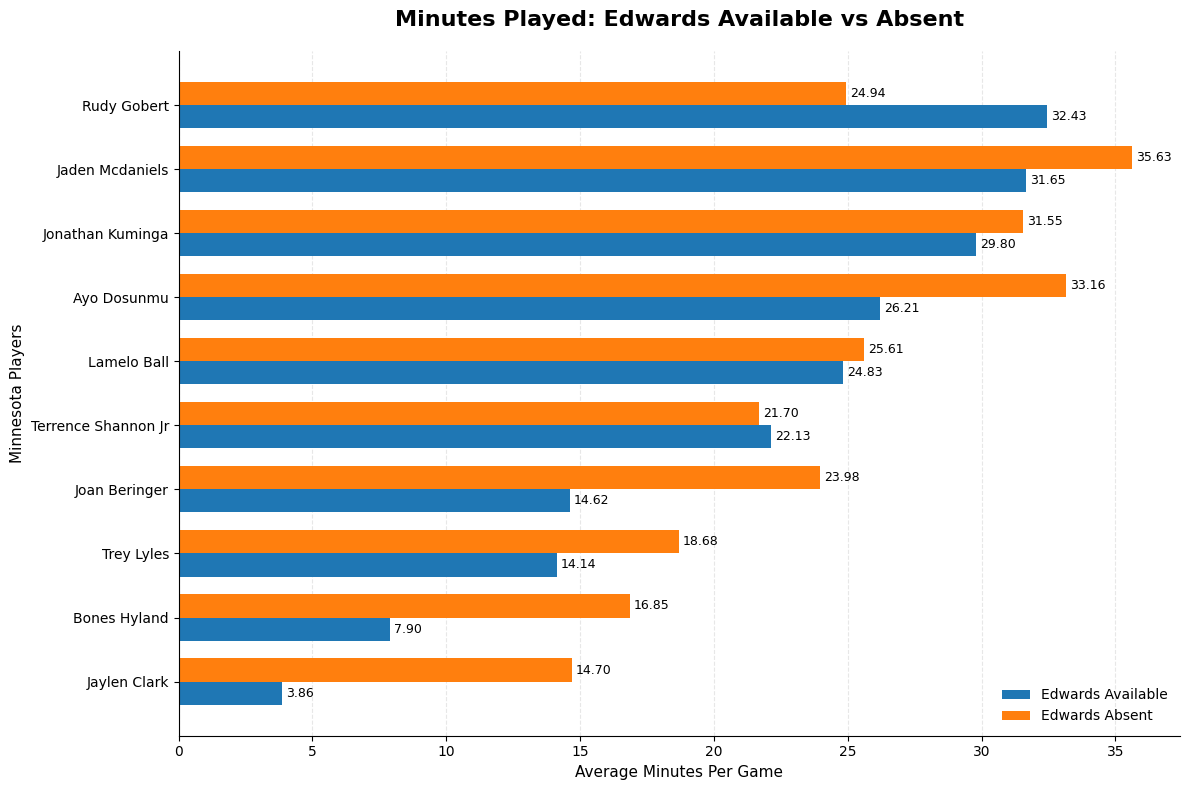

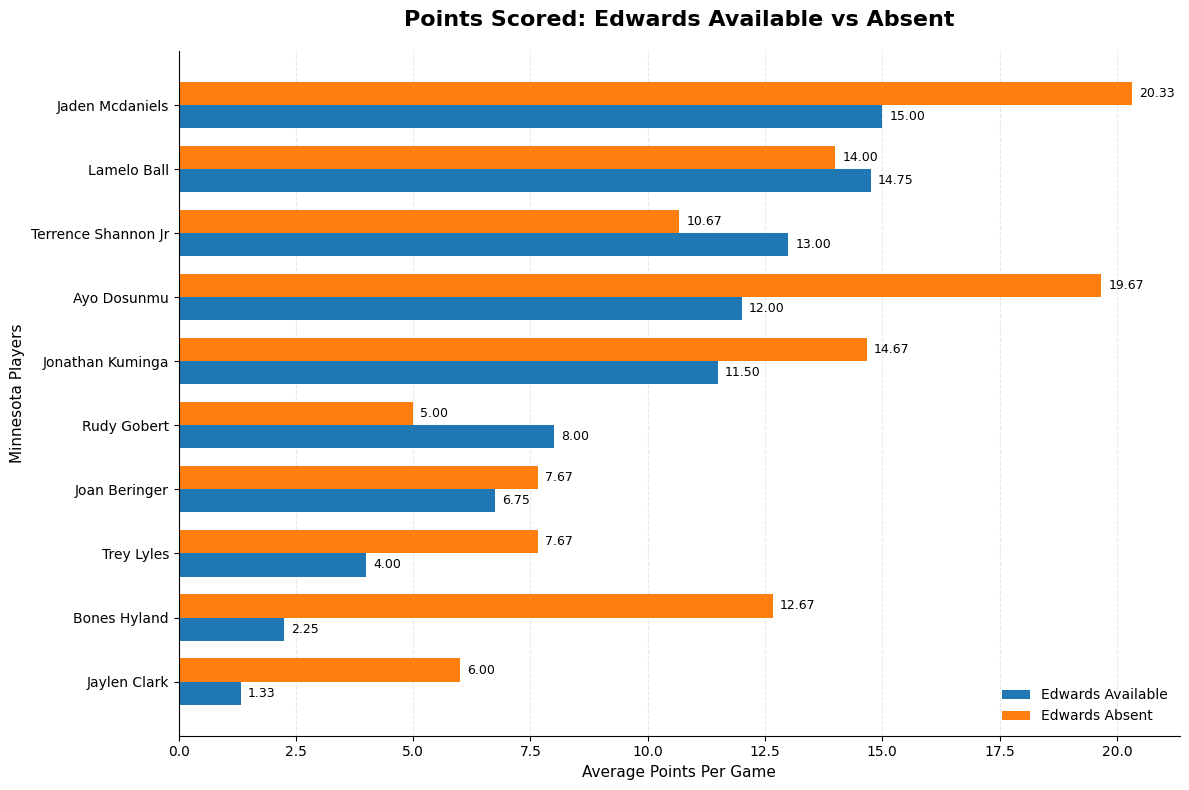

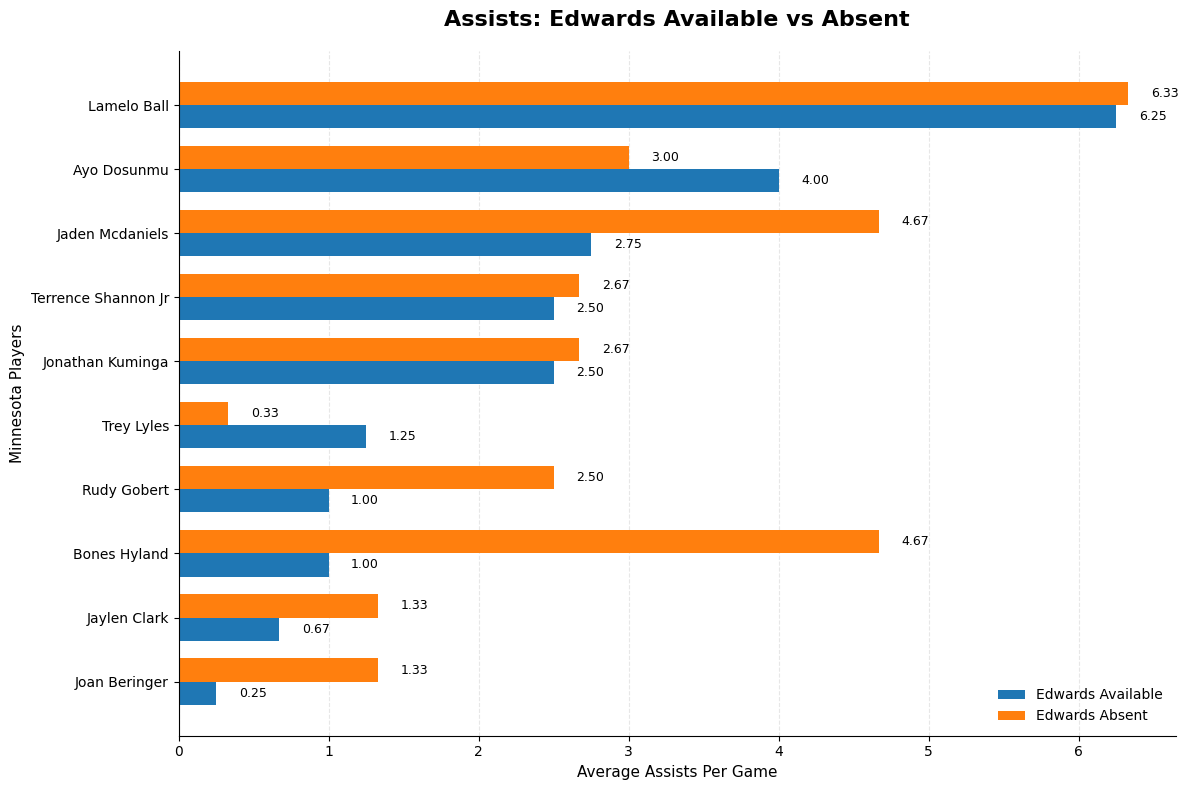

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Keep players with sufficient appearances in both conditions
eligible = comparison[
    (comparison["GP_with"] >= 2) &
    (comparison["GP_without"] >= 2)
].copy()

# Sort players by their average value across both conditions
chart_configs = [
    {
        "with": "MPG_with",
        "without": "MPG_without",
        "title": "Minutes Played: Edwards Available vs Absent",
        "xlabel": "Average Minutes Per Game",
        "filename": "minutes_comparison"
    },
    {
        "with": "PPG_with",
        "without": "PPG_without",
        "title": "Points Scored: Edwards Available vs Absent",
        "xlabel": "Average Points Per Game",
        "filename": "points_comparison"
    },
    {
        "with": "APG_with",
        "without": "APG_without",
        "title": "Assists: Edwards Available vs Absent",
        "xlabel": "Average Assists Per Game",
        "filename": "assists_comparison"
    }
]

for config in chart_configs:

    data = eligible.sort_values(
        config["with"], ascending=True
    ).copy()

    y = np.arange(len(data))
    bar_height = 0.36

    fig, ax = plt.subplots(figsize=(12, 8))

    bars_with = ax.barh(
        y - bar_height / 2,
        data[config["with"]],
        height=bar_height,
        label="Edwards Available"
    )

    bars_without = ax.barh(
        y + bar_height / 2,
        data[config["without"]],
        height=bar_height,
        label="Edwards Absent"
    )

    # Add values at the end of each bar
    for bars in [bars_with, bars_without]:
        for bar in bars:
            width = bar.get_width()

            ax.text(
                width + 0.15,
                bar.get_y() + bar.get_height() / 2,
                f"{width:.2f}",
                va="center",
                fontsize=9
            )

    ax.set_yticks(y)
    ax.set_yticklabels(data["player_name"])

    ax.set_title(
        config["title"],
        fontsize=16,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel(config["xlabel"], fontsize=11)
    ax.set_ylabel("Minnesota Players", fontsize=11)

    ax.legend(loc="lower right", frameon=False)
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig(
        f"{config['filename']}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()